# Projet DVF : étape 2, baselines et modèles
Entrée : `data/dvf_clean.parquet` (produit à l'étape 1).

**Protocole**
- Cible : `log(prix_m2)` (on réexprime les prédictions en €/m² pour les métriques).
- Split **temporel** : entraînement 2022-2023, validation 2024 (réglage, arrêt anticipé), **test 2025**.
- Modèles finaux réentraînés sur 2022-2024, évalués sur 2025.
- Aucune variable « année » : un arbre ne sait pas extrapoler vers 2025.

Installation si besoin : `pip install lightgbm catboost scikit-learn pyarrow matplotlib optuna shap`

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, os
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import lightgbm as lgb
from catboost import CatBoostRegressor
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
SEED = 42
np.random.seed(SEED)

df = pd.read_parquet('data/dvf_clean.parquet')
print(df.shape)
df.head(3)

(30125, 18)


,date,annee,mois,trimestre,annee_mois,insee,commune,code_postal,type_local,surface_bati,surface_carrez,pieces,surface_terrain,nb_dependances,a_dependance,log_surface,valeur_fonciere,prix_m2
0,2022-01-03,2022,1,1,2022-01,01053,BOURG-EN-BRESSE,01000,Appartement,24.0,24.10,1.0,0.0,0,0,3.178054,55000.0,2291.666667
1,2022-01-03,2022,1,1,2022-01,01398,SAVIGNEUX,01480,Appartement,140.0,123.23,3.0,172.0,0,0,4.941642,143000.0,1021.428571
2,2022-01-04,2022,1,1,2022-01,01053,BOURG-EN-BRESSE,01000,Appartement,46.0,70.02,1.0,0.0,1,1,3.828641,134000.0,2913.043478


## 1. Variables et split temporel

In [2]:
df['y'] = np.log(df['prix_m2'])
df['carrez_dispo'] = df['surface_carrez'].notna().astype(int)
df['log_terrain'] = np.log1p(df['surface_terrain'])
df['mois_sin'] = np.sin(2*np.pi*df['mois']/12)
df['mois_cos'] = np.cos(2*np.pi*df['mois']/12)

# Pays de Gex (zone frontalière) : utilisé pour ANALYSER les erreurs, pas comme variable d'entrée
CP_GEX = {'01170','01210','01220','01280','01630','01710'}
df['pays_de_gex'] = df['code_postal'].isin(CP_GEX).astype(int)

NUM = ['surface_bati','log_surface','pieces','surface_terrain','log_terrain','nb_dependances',
       'a_dependance','surface_carrez','carrez_dispo','mois','mois_sin','mois_cos']
CAT = ['type_local','commune']
FEATS = NUM + CAT

train = df[df.annee <= 2023]; val = df[df.annee == 2024]
trainval = df[df.annee <= 2024]; test = df[df.annee == 2025]
for n, d in [('train',train),('val',val),('trainval',trainval),('test',test)]:
    print(f'{n:9s}', len(d))

train     16062
val       6415
trainval  22477
test      7648


## 2. Métriques

In [3]:
def metrics(y_true, y_pred):
    e = y_pred - y_true
    ape = np.abs(e) / y_true
    return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e**2).mean()),
            'MAPE %': ape.mean()*100, 'MedAPE %': np.median(ape)*100,
            '±10 %': (ape <= .10).mean()*100, '±20 %': (ape <= .20).mean()*100,
            'R2 (log)': 1 - ((np.log(y_pred)-np.log(y_true))**2).sum() / ((np.log(y_true)-np.log(y_true).mean())**2).sum()}

results, preds = {}, {}
def enregistrer(nom, pred_m2):
    preds[nom] = np.asarray(pred_m2)
    results[nom] = metrics(test['prix_m2'].values, preds[nom])
    return pd.Series(results[nom]).round(2)

## 3. Baselines
- B0 : médiane du type de bien.
- B1 : médiane commune × type, lissée vers la médiane du type quand la commune a peu de ventes.
- B2 : Ridge sur le log du prix.

In [4]:
# B0
med_type = trainval.groupby('type_local')['prix_m2'].median()
enregistrer('B0 médiane par type', test['type_local'].map(med_type))

# B1 : médiane commune x type, lissée (k = poids de la médiane globale du type)
def fit_med_commune(tr):
    stats = tr.groupby(['commune','type_local'])['prix_m2'].agg(['median','count']).reset_index()
    return tr.groupby('type_local')['prix_m2'].median(), stats

def pred_med_commune(X, g_type, stats, k=5):
    m = X[['commune','type_local']].merge(stats, on=['commune','type_local'], how='left')
    base = X['type_local'].map(g_type).values
    n = m['count'].fillna(0).values
    med = m['median'].fillna(0).values
    w = n / (n + k)
    return w*med + (1-w)*base

g, st = fit_med_commune(trainval)
enregistrer('B1 médiane commune×type', pred_med_commune(test, g, st))

# B2 : Ridge (alpha choisi sur la validation 2024)
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=3), CAT)])
meilleur = None
for a in [0.3, 1, 3, 10, 30, 100]:
    pipe = Pipeline([('p', prep), ('m', Ridge(alpha=a))]).fit(train[FEATS], train['y'])
    rmse = np.sqrt(((pipe.predict(val[FEATS]) - val['y'])**2).mean())
    if meilleur is None or rmse < meilleur[0]: meilleur = (rmse, a)
print('alpha Ridge retenu :', meilleur[1], '| RMSE log validation :', round(meilleur[0], 4))
ridge = Pipeline([('p', prep), ('m', Ridge(alpha=meilleur[1]))]).fit(trainval[FEATS], trainval['y'])
enregistrer('B2 Ridge (log)', np.exp(ridge.predict(test[FEATS])))
pd.DataFrame(results).T.round(2)

alpha Ridge retenu : 3 | RMSE log validation : 0.3277


,MAE,RMSE,MAPE %,MedAPE %,±10 %,±20 %,R2 (log)
B0 médiane par type,1029.21,1378.18,41.73,30.59,18.62,35.12,0.00
B1 médiane commune×type,628.37,832.09,28.80,17.89,29.39,55.36,0.50
B2 Ridge (log),598.61,793.07,25.49,17.48,29.04,56.35,0.57


## 4. LightGBM
`commune` et `type_local` sont des variables catégorielles natives. Les communes absentes de l'entraînement sont traitées comme valeur manquante.

In [5]:
cats = {c: trainval[c].astype('category').cat.categories for c in CAT}
def prep_lgb(d):
    X = d[FEATS].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c], categories=cats[c])
    return X

LGB_PARAMS = dict(objective='regression', learning_rate=0.03, num_leaves=31, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  cat_smooth=20, cat_l2=10, min_data_per_group=10, random_state=SEED, verbose=-1)

### 4b. (Optionnel) Réglage Optuna

In [6]:
RUN_OPTUNA = False     # passe à True pour lancer le réglage (quelques minutes)
N_TRIALS = 40

if RUN_OPTUNA:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(trial):
        p = dict(LGB_PARAMS,
                 learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
                 num_leaves=trial.suggest_int('num_leaves', 8, 128, log=True),
                 min_child_samples=trial.suggest_int('min_child_samples', 5, 80),
                 subsample=trial.suggest_float('subsample', 0.5, 1.0),
                 colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
                 reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 30, log=True),
                 cat_smooth=trial.suggest_float('cat_smooth', 1, 100, log=True))
        m = lgb.LGBMRegressor(n_estimators=5000, **p)
        m.fit(prep_lgb(train), train['y'], eval_set=[(prep_lgb(val), val['y'])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        return np.sqrt(((m.predict(prep_lgb(val)) - val['y'])**2).mean())
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS)
    LGB_PARAMS.update(study.best_params)
    print('Meilleurs paramètres :', study.best_params, '| RMSE val :', round(study.best_value, 4))

In [7]:
# 1) arrêt anticipé sur la validation 2024
m_es = lgb.LGBMRegressor(n_estimators=5000, **LGB_PARAMS)
m_es.fit(prep_lgb(train), train['y'], eval_set=[(prep_lgb(val), val['y'])],
         callbacks=[lgb.early_stopping(100, verbose=False)])
BEST_IT = int(m_es.best_iteration_)
print('Nombre d\'arbres retenu :', BEST_IT)

# 2) modèle final sur 2022-2024
lgb_final = lgb.LGBMRegressor(n_estimators=BEST_IT, **LGB_PARAMS).fit(prep_lgb(trainval), trainval['y'])
enregistrer('LightGBM', np.exp(lgb_final.predict(prep_lgb(test))))

Nombre d'arbres retenu : 431


MAE         569.73
RMSE        767.43
MAPE %       24.27
MedAPE %     16.26
±10 %        31.32
±20 %        59.61
R2 (log)      0.60
dtype: float64

## 5. CatBoost (gère bien les catégories rares comme la commune)

In [8]:
def prep_cb(d):
    X = d[FEATS].copy()
    for c in CAT: X[c] = X[c].astype(str)
    return X

cb_es = CatBoostRegressor(iterations=3000, learning_rate=0.05, depth=6, loss_function='RMSE',
                          random_seed=SEED, verbose=0, od_type='Iter', od_wait=100)
cb_es.fit(prep_cb(train), train['y'], cat_features=CAT, eval_set=(prep_cb(val), val['y']))
CB_IT = max(int(cb_es.get_best_iteration()), 50)
print('Itérations CatBoost :', CB_IT)

cb_final = CatBoostRegressor(iterations=CB_IT, learning_rate=0.05, depth=6, loss_function='RMSE',
                             random_seed=SEED, verbose=0)
cb_final.fit(prep_cb(trainval), trainval['y'], cat_features=CAT)
enregistrer('CatBoost', np.exp(cb_final.predict(prep_cb(test))))

# moyenne des deux modèles
enregistrer('Moyenne LGBM + CatBoost', np.sqrt(preds['LightGBM'] * preds['CatBoost']))

Itérations CatBoost : 740


MAE         568.02
RMSE        765.39
MAPE %       24.22
MedAPE %     16.18
±10 %        32.17
±20 %        59.44
R2 (log)      0.60
dtype: float64

## 6. Comparaison des modèles sur le test 2025

,MAE,RMSE,MAPE %,MedAPE %,±10 %,±20 %,R2 (log)
Moyenne LGBM + CatBoost,568.02,765.39,24.22,16.18,32.17,59.44,0.60
LightGBM,569.73,767.43,24.27,16.26,31.32,59.61,0.60
CatBoost,578.67,779.88,24.72,16.51,31.37,58.49,0.59
B2 Ridge (log),598.61,793.07,25.49,17.48,29.04,56.35,0.57
B1 médiane commune×type,628.37,832.09,28.80,17.89,29.39,55.36,0.50
B0 médiane par type,1029.21,1378.18,41.73,30.59,18.62,35.12,0.00


Meilleur modèle (MedAPE) : Moyenne LGBM + CatBoost


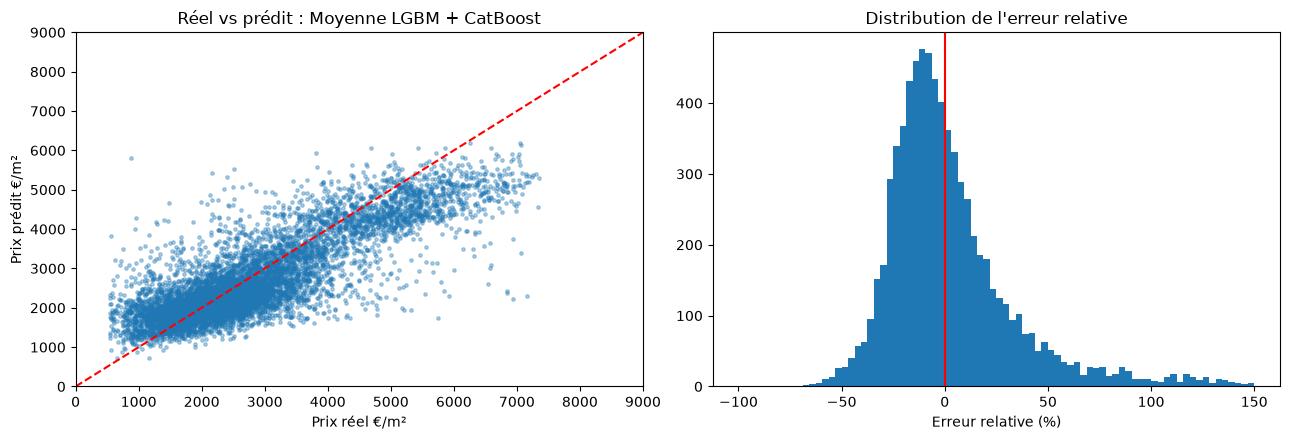

In [9]:
res = pd.DataFrame(results).T.round(2).sort_values('MedAPE %')
display(res)
MEILLEUR = res.index[0]
print('Meilleur modèle (MedAPE) :', MEILLEUR)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
p = preds[MEILLEUR]; t = test['prix_m2'].values
ax[0].scatter(t, p, s=6, alpha=.35); lim = [0, 9000]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel('Prix réel €/m²'); ax[0].set_ylabel('Prix prédit €/m²'); ax[0].set_title(f'Réel vs prédit : {MEILLEUR}')
ax[1].hist((p - t) / t * 100, bins=80, range=(-100, 150)); ax[1].axvline(0, color='r')
ax[1].set_xlabel('Erreur relative (%)'); ax[1].set_title('Distribution de l\'erreur relative')
plt.tight_layout(); plt.show()

## 7. Marge d'erreur : intervalle de confiance des métriques (bootstrap)
L'incertitude vient ici du nombre limité de ventes dans le jeu de test.

In [10]:
rng = np.random.default_rng(SEED)
t = test['prix_m2'].values; p = preds[MEILLEUR]
boot = []
for _ in range(1000):
    i = rng.integers(0, len(t), len(t))
    m = metrics(t[i], p[i]); boot.append([m['MAE'], m['MAPE %'], m['MedAPE %'], m['±20 %']])
boot = np.array(boot)
ic = pd.DataFrame({'estimation': [metrics(t, p)[k] for k in ['MAE','MAPE %','MedAPE %','±20 %']],
                   'IC95 bas': np.percentile(boot, 2.5, axis=0),
                   'IC95 haut': np.percentile(boot, 97.5, axis=0)},
                  index=['MAE (€/m²)','MAPE %','MedAPE %','part ±20 %']).round(2)
ic

,estimation,IC95 bas,IC95 haut
MAE (€/m²),568.02,557.33,579.22
MAPE %,24.22,23.53,25.00
MedAPE %,16.18,15.78,16.64
part ±20 %,59.44,58.38,60.53


## 8. Où la marge d'erreur est-elle grande ? (erreur par segment)

In [11]:
seg = test.copy()
seg['pred'] = preds[MEILLEUR]
seg['ape'] = np.abs(seg['pred'] - seg['prix_m2']) / seg['prix_m2'] * 100
seg['biais %'] = (seg['pred'] - seg['prix_m2']) / seg['prix_m2'] * 100
seg['tranche_surface'] = pd.cut(seg['surface_bati'], [0, 40, 70, 100, 150, 600])
seg['quartile_prix_reel'] = pd.qcut(seg['prix_m2'], 4, labels=['Q1 bas','Q2','Q3','Q4 haut'])

def tableau(col, min_n=1):
    t = seg.groupby(col, observed=True).agg(n=('ape','size'), MAPE=('ape','mean'),
                                           MedAPE=('ape','median'), biais_median=('biais %','median')).round(1)
    return t[t.n >= min_n]

for col in ['type_local', 'pays_de_gex', 'tranche_surface', 'quartile_prix_reel']:
    print(f'--- par {col}'); display(tableau(col))
print('--- 15 communes les plus vendues (test)')
top = seg['commune'].value_counts().head(15).index
display(tableau('commune').loc[top].sort_values('MedAPE'))

--- par type_local


,n,MAPE,MedAPE,biais_median
type_local,,,,
Appartement,2768,19.9,15.3,-5.4
Maison,4880,26.7,16.8,-3.1


--- par pays_de_gex


,n,MAPE,MedAPE,biais_median
pays_de_gex,,,,
0,6306,25.6,17.0,-2.3
1,1342,17.9,13.5,-8.8


--- par tranche_surface


,n,MAPE,MedAPE,biais_median
tranche_surface,,,,
"(0, 40]",371,21.3,15.7,-4.4
"(40, 70]",1694,23.2,16.6,-6.5
"(70, 100]",2709,24.3,16.3,-3.6
"(100, 150]",2241,24.5,15.7,-3.1
"(150, 600]",633,27.6,16.7,-1.1


--- par quartile_prix_reel


,n,MAPE,MedAPE,biais_median
quartile_prix_reel,,,,
Q1 bas,1912,45.6,27.8,26.8
Q2,1913,16.4,12.1,-2.0
Q3,1911,17.8,16.2,-12.3
Q4 haut,1912,17.1,14.7,-13.1


--- 15 communes les plus vendues (test)


,n,MAPE,MedAPE,biais_median
commune,,,,
PREVESSIN-MOENS,114,14.0,11.8,-5.1
LAGNIEU,100,17.3,12.0,-2.0
GEX,226,16.9,12.6,-8.7
FERNEY-VOLTAIRE,188,18.2,13.0,-3.2
MIRIBEL,115,20.5,13.0,-3.6
ST-GENIS-POUILLY,164,17.2,13.1,-11.1
MEXIMIEUX,87,22.1,13.6,4.0
MONTLUEL,99,23.1,14.9,-2.9
DIVONNE-LES-BAINS,171,23.0,15.2,-9.3


## 9. Courbe d'apprentissage : a-t-on assez de lignes ?
On entraîne sur une fraction croissante de 2022-2024 et on mesure l'erreur sur 2025. Si la courbe plafonne, plus de données n'aideront pas.

MAPE %       MedAPE %      
                 mean   std     mean   std
fraction n                                
0.1      2248   33.65  0.40    22.87  0.20
0.2      4495   29.26  0.32    19.44  0.29
0.3      6743   27.19  0.19    18.10  0.19
0.5      11238  25.63  0.09    17.12  0.16
0.7      15734  25.00  0.06    16.69  0.06
1.0      22477  24.25  0.01    16.27  0.02

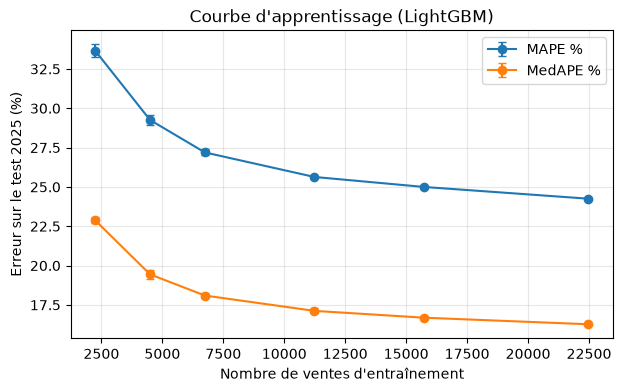

In [12]:
fractions = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
rows = []
for f in fractions:
    for s in range(3):
        sub = trainval.sample(frac=f, random_state=SEED + s) if f < 1 else trainval
        m = lgb.LGBMRegressor(n_estimators=BEST_IT, **dict(LGB_PARAMS, random_state=SEED + s))
        m.fit(prep_lgb(sub), sub['y'])
        mm = metrics(test['prix_m2'].values, np.exp(m.predict(prep_lgb(test))))
        rows.append({'fraction': f, 'n': len(sub), 'MAPE %': mm['MAPE %'], 'MedAPE %': mm['MedAPE %']})
lc = pd.DataFrame(rows).groupby(['fraction','n']).agg(['mean','std']).round(2)
display(lc)

g = pd.DataFrame(rows).groupby('n')[['MAPE %','MedAPE %']].agg(['mean','std'])
plt.figure(figsize=(7,4))
for c in ['MAPE %','MedAPE %']:
    plt.errorbar(g.index, g[(c,'mean')], yerr=g[(c,'std')], marker='o', capsize=3, label=c)
plt.xlabel('Nombre de ventes d\'entraînement'); plt.ylabel('Erreur sur le test 2025 (%)')
plt.title('Courbe d\'apprentissage (LightGBM)'); plt.legend(); plt.grid(alpha=.3); plt.show()

## 10. Intervalles de prédiction (80 %)
Deux méthodes :
1. **Conformelle (split)** : on calibre l'écart sur la validation 2024.
2. **Régression quantile** LightGBM (quantiles 10 % et 90 %).

In [13]:
ALPHA = 0.20
# 1) conformelle : modèle entraîné sur 2022-2023, résidus absolus (log) sur 2024
res_val = np.abs(val['y'].values - m_es.predict(prep_lgb(val)))
n = len(res_val)
q = np.quantile(res_val, min(1, np.ceil((n + 1) * (1 - ALPHA)) / n))
centre = lgb_final.predict(prep_lgb(test))
lo_c, hi_c = np.exp(centre - q), np.exp(centre + q)

# 2) quantiles
def fit_q(a):
    return lgb.LGBMRegressor(n_estimators=BEST_IT, **dict(LGB_PARAMS, objective='quantile', alpha=a)).fit(
        prep_lgb(trainval), trainval['y'])
lo_q = np.exp(fit_q(ALPHA/2).predict(prep_lgb(test)))
hi_q = np.exp(fit_q(1 - ALPHA/2).predict(prep_lgb(test)))
lo_q, hi_q = np.minimum(lo_q, np.exp(centre)), np.maximum(hi_q, np.exp(centre))

t = test['prix_m2'].values
def couverture(lo, hi):
    return {'couverture %': ((t >= lo) & (t <= hi)).mean()*100,
            'largeur relative médiane %': np.median((hi - lo) / np.exp(centre))*100}
print('Objectif de couverture :', (1-ALPHA)*100, '%')
display(pd.DataFrame({'conformelle': couverture(lo_c, hi_c), 'quantiles': couverture(lo_q, hi_q)}).T.round(1))

cov = test.assign(ok_conf=((t >= lo_c) & (t <= hi_c)), ok_q=((t >= lo_q) & (t <= hi_q)))
print('Couverture par segment :')
display((cov.groupby('type_local')[['ok_conf','ok_q']].mean()*100).round(1))
display((cov.groupby('pays_de_gex')[['ok_conf','ok_q']].mean()*100).round(1))

ex = test[['commune','type_local','surface_bati','prix_m2']].head(5).copy()
ex['estimation'] = np.exp(centre[:5]).round(0); ex['bas_80%'] = lo_c[:5].round(0); ex['haut_80%'] = hi_c[:5].round(0)
ex

Objectif de couverture : 80.0 %


,couverture %,largeur relative médiane %
conformelle,82.3,73.5
quantiles,76.3,62.2


Couverture par segment :


,ok_conf,ok_q
type_local,,
Appartement,87.0,73.6
Maison,79.7,77.8


,ok_conf,ok_q
pays_de_gex,,
0,79.9,77.7
1,94.0,69.6


,commune,type_local,surface_bati,prix_m2,estimation,bas_80%,haut_80%
8161,MONTANGES,Appartement,87.0,2068.965517,1450.0,1012.0,2078.0
8162,GEX,Appartement,35.0,5228.571429,4429.0,3092.0,6345.0
8163,AMBERIEUX-EN-DOMBES,Appartement,49.0,2692.597959,2934.0,2048.0,4203.0
8164,PONT-DE-VEYLE,Appartement,78.0,2217.948718,1599.0,1116.0,2291.0
8165,CHALLEX,Appartement,67.0,6189.029851,4311.0,3009.0,6176.0


## 11. Interprétation : importance des variables

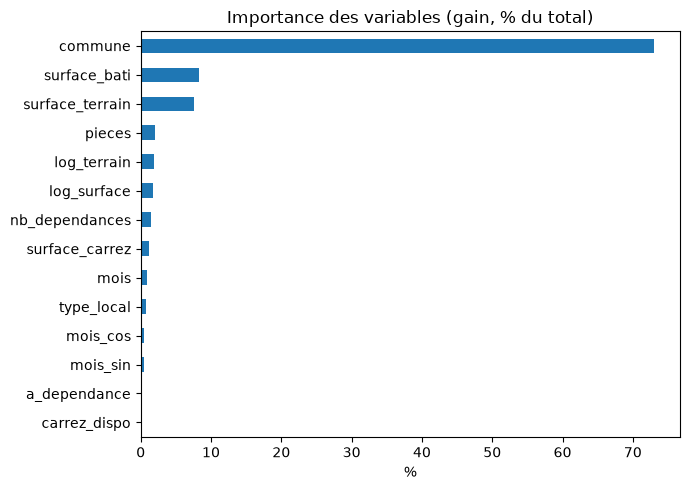

In [14]:
imp = pd.Series(lgb_final.booster_.feature_importance('gain'), index=FEATS).sort_values()
(imp / imp.sum() * 100).plot.barh(figsize=(7, 5), title='Importance des variables (gain, % du total)')
plt.xlabel('%'); plt.tight_layout(); plt.show()

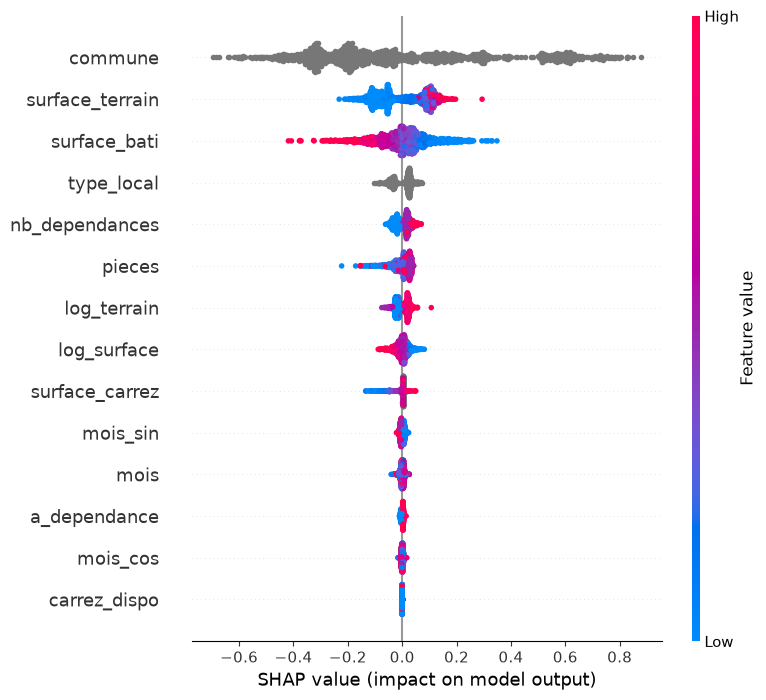

In [15]:
# SHAP (optionnel) : pip install shap
try:
    import shap
    ech = prep_lgb(test).sample(min(1500, len(test)), random_state=SEED)
    sv = shap.TreeExplainer(lgb_final).shap_values(ech)
    shap.summary_plot(sv, ech, show=True)
except ImportError:
    print('shap non installé : pip install shap')

## 12. Sauvegarde

In [16]:
os.makedirs('data', exist_ok=True)
res.to_csv('data/etape2_metriques.csv')
out = test[['date','commune','type_local','surface_bati','prix_m2']].copy()
for k, v in preds.items(): out['pred_' + k.split()[0]] = v
out['lo80_conf'], out['hi80_conf'] = lo_c, hi_c
out.to_csv('data/etape2_predictions_test.csv', index=False)
print('Sauvegardé : data/etape2_metriques.csv et data/etape2_predictions_test.csv')

Sauvegardé : data/etape2_metriques.csv et data/etape2_predictions_test.csv


## Ce que tu dois retenir pour ton rapport
1. Le gain de chaque modèle **par rapport à la baseline** B1 (médiane commune × type).
2. La **marge d'erreur** : intervalle de confiance bootstrap, erreur par segment, couverture des intervalles.
3. La courbe d'apprentissage : plafond atteint ou non.
4. Étape 3 : ajout des variables externes (coordonnées, distance à Genève, indice des prix, taux, population) et mesure du gain par rapport aux chiffres de cette étape.